In [ ]:
import random
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from keras import models, layers, callbacks

In [2]:
tf.keras.mixed_precision.set_global_policy('float64')

In [2]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()

In [ ]:
current_dir = Path.cwd()

In [ ]:
training_dir = str(current_dir / "1L_train")
train_emb_dir = training_dir + 'train_emb.npy'
train_feat_dir = training_dir + 'train_feat.npy'
y_train_dir = training_dir + 'y_train.npy'
valid_emb_dir = training_dir + 'valid_emb.npy'
valid_feat_dir = training_dir + 'valid_feat.npy'
y_valid_dir = training_dir + 'y_valid.npy'
model_dir = training_dir + 'model.keras'
history_dir = training_dir + 'history.csv'

test_emb_dir = str(current_dir.parent / 'datasets/First Level/pre_processed/test_emb.npy')
test_feat_dir = str(current_dir.parent / 'datasets/First Level/pre_processed/test_feat.npy')
y_test_dir = str(current_dir.parent / 'datasets/First Level/y_test.npy')

In [5]:
from kerastuner import Hyperband
desc_dim = 887
emb_dim = 1024
dtype = tf.float32
def build_model(hp) -> keras.Model:
    input_desc = layers.Input(shape=(desc_dim,), dtype=dtype)
    input_emb = layers.Input(shape=(emb_dim,), dtype=dtype)
    
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    activation = hp.Choice('activation', values=['relu', 'swish', 'leaky_relu', 'elu'])
    l2_reg = hp.Float('l2_reg', min_value=1e-5, max_value=1e-2, sampling='log')
    noise_std = hp.Float('noise_std', min_value=0.01, max_value=0.1, step=0.03)

    noisy_emb = layers.GaussianNoise(noise_std)(input_emb)
    noisy_desc = layers.GaussianNoise(noise_std)(input_desc)

    y = noisy_emb
    units_e = hp.Int(f'emb_units_start', min_value=256, max_value=768, step=128)
    for i in range(hp.Int('emb_layers', 1, 3)):
        y = layers.Dense(units_e // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(y)
        y = layers.BatchNormalization()(y)
        y = layers.Activation(activation)(y)
        y = layers.Dropout(dropout_rate)(y)

    x = noisy_desc
    units_d = hp.Int(f'desc_units_start', min_value=128, max_value=512, step=128)
    for i in range(hp.Int('desc_layers', 1, 3)):
        x = layers.Dense(units_d // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation(activation)(x)
        x = layers.Dropout(dropout_rate)(x)

    combined = layers.Concatenate()([y, x])
    
    z = combined
    units_h = hp.Int(f'head_units_start', min_value=64, max_value=256, step=64)
    for i in range(hp.Int('head_layers', 1, 3)):
        z = layers.Dense(units_h // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(z)
        z = layers.BatchNormalization()(z)
        z = layers.Activation(activation)(z)
        z = layers.Dropout(dropout_rate)(z)

    output = layers.Dense(1, activation='sigmoid', dtype=dtype)(z)
    model = models.Model(inputs=[input_emb, input_desc], outputs=output, name='enzyme_classifier_dual')
    learning_rate = hp.Float('learning_rate', min_value=1e-5, max_value=1e-3, sampling='log')
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
        metrics=[
            'accuracy', 
            keras.metrics.Precision(name='precision'), 
            keras.metrics.Recall(name='recall')
        ]
    )
    return model
tuner = Hyperband(
        build_model,
        objective = "val_loss",
        max_epochs=50,
        factor=3,
        seed=42,
        directory='tunning_FL',
        project_name='enzyme_dual_branch'
    )
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
lr = 0.0001
for param in best_hp.values:
    print(f"{param}: {best_hp.get(param)}")
    if param == 'learning_rate':
        lr = best_hp.get(param)

C:\Users\Victor\AppData\Local\Temp\ipykernel_12412\4170070597.py:1: DeprecationWarning: `import kerastuner` is deprecated, please use `import keras_tuner`.
  from kerastuner import Hyperband


Reloading Tuner from tunning_FL\enzyme_dual_branch\tuner0.json
Best Hyperparameters:
dropout_rate: 0.30000000000000004
activation: swish
l2_reg: 1.6308979287756596e-05
noise_std: 0.01
emb_units_start: 640
emb_layers: 3
desc_units_start: 512
desc_layers: 1
head_units_start: 64
head_layers: 1
learning_rate: 0.0005241515692754443
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0046


## Visualizing training

In [4]:
history = pd.read_csv(history_dir)
history.head(37)

,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.903287,0.246238,0.932553,0.179920
1,1,0.945483,0.149025,0.946115,0.155061
2,2,0.960439,0.113905,0.952374,0.157856
3,3,0.969289,0.093942,0.953009,0.175695
4,4,0.974934,0.080600,0.954960,0.186753
5,5,0.978991,0.070985,0.955368,0.202398
6,6,0.982058,0.062418,0.955822,0.216937


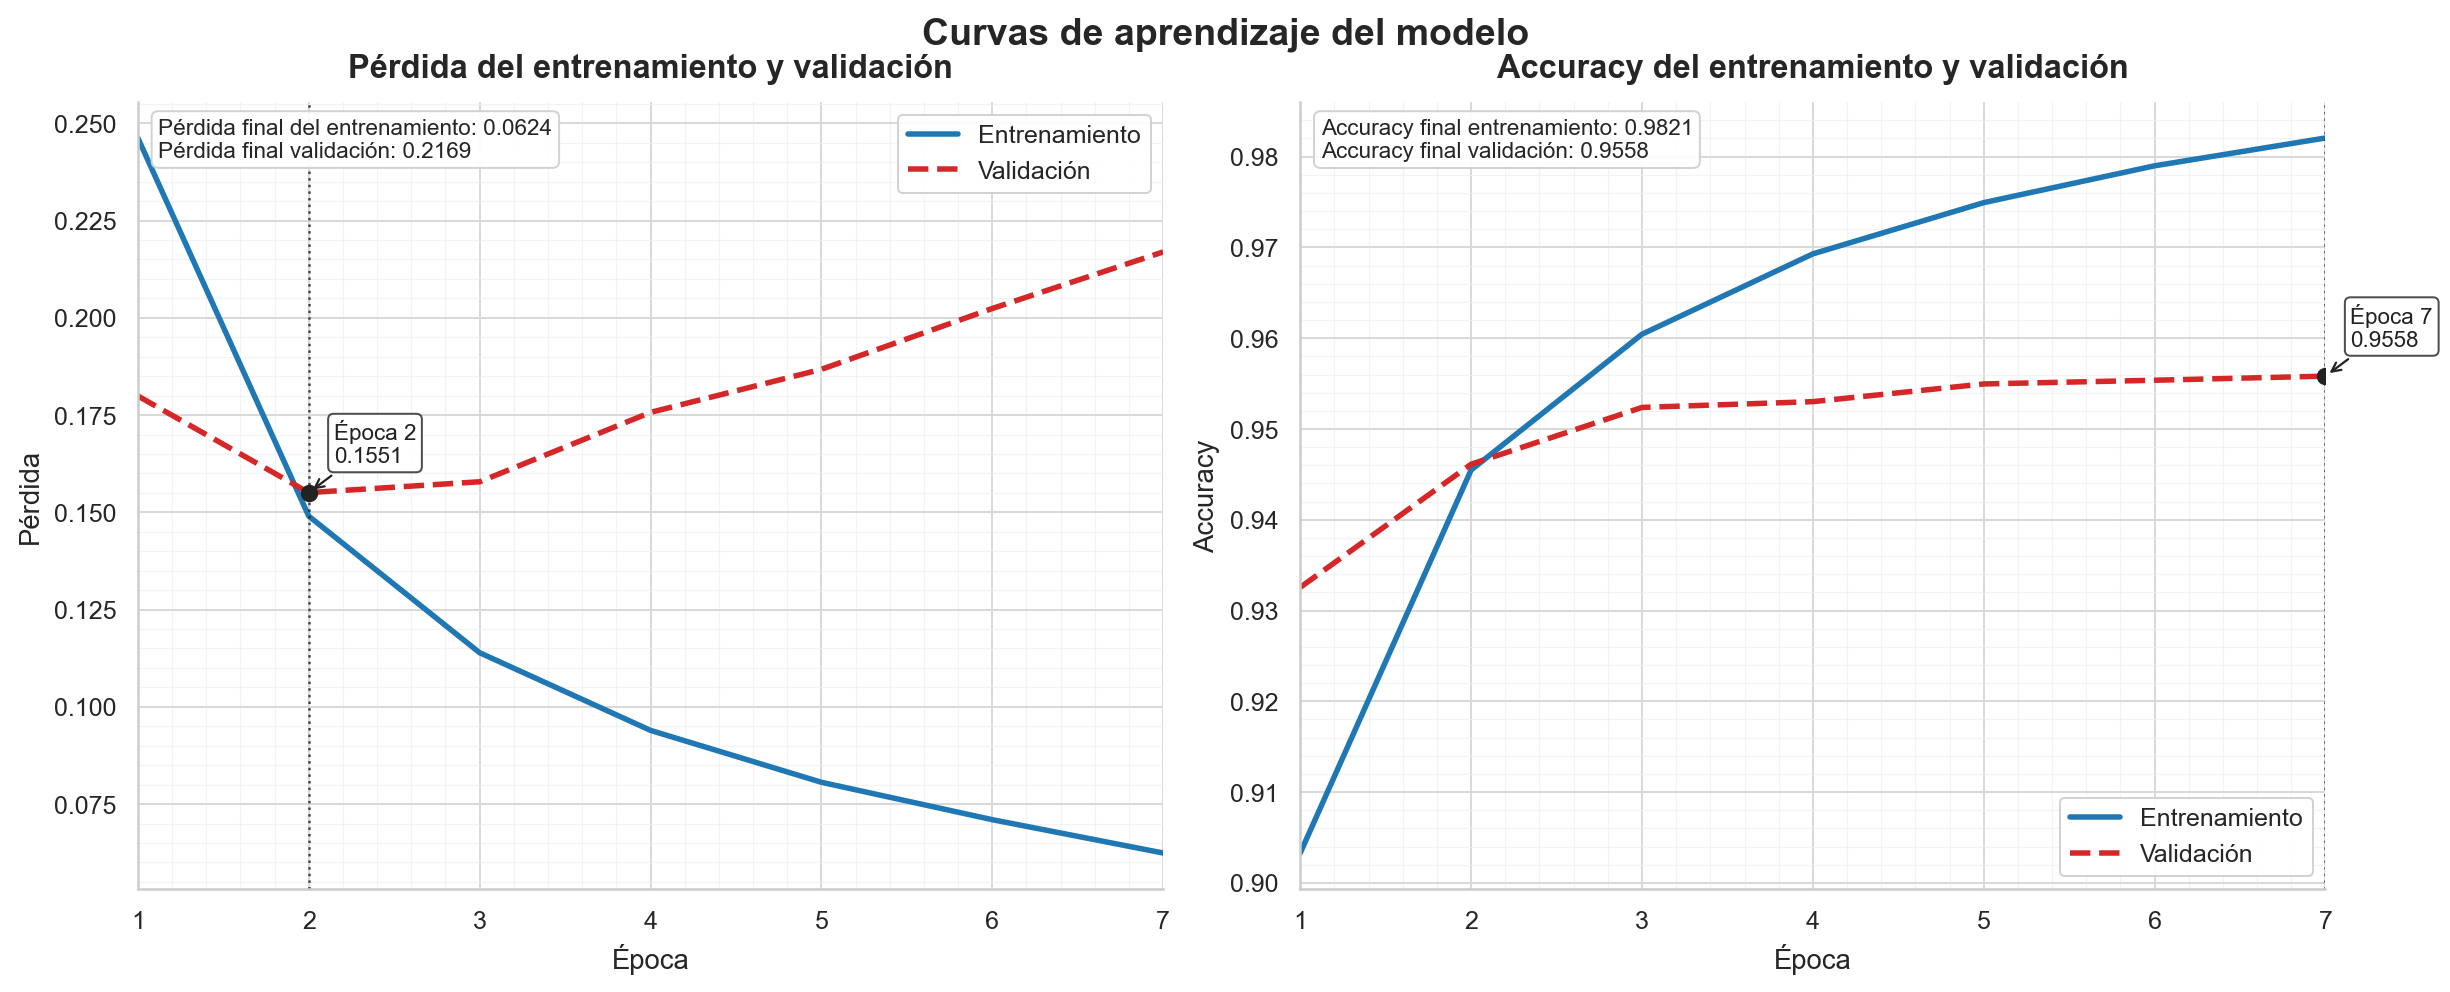

In [5]:
from matplotlib.ticker import MaxNLocator

epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

best_val_loss_idx = history['val_loss'].idxmin()
best_val_acc_idx = history['val_accuracy'].idxmax()

train_color = '#1f77b4'
valid_color = '#d62728'
highlight_color = '#222222'

sns.set_theme(style='whitegrid', context='paper')
plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

metric_specs = [
    {
        'ax': axes[0],
        'train_key': 'loss',
        'valid_key': 'val_loss',
        'title': 'Pérdida del entrenamiento y validación',
        'ylabel': 'Pérdida',
        'best_idx': best_val_loss_idx,
    },
    {
        'ax': axes[1],
        'train_key': 'accuracy',
        'valid_key': 'val_accuracy',
        'title': 'Accuracy del entrenamiento y validación',
        'ylabel': 'Accuracy',
        'best_idx': best_val_acc_idx,
    },
]

for spec in metric_specs:
    ax = spec['ax']
    train_values = history[spec['train_key']].to_numpy()
    valid_values = history[spec['valid_key']].to_numpy()
    best_epoch = int(epochs[spec['best_idx']])
    best_value = valid_values[spec['best_idx']]

    ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
    ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
    ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
    ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
    ax.annotate(
        f"Época {best_epoch}\n{best_value:.4f}",
        xy=(best_epoch, best_value),
        xytext=(10, 12),
        textcoords='offset points',
        fontsize=9,
        color=highlight_color,
        bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
        arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
    )

    ax.set_title(spec['title'], pad=10, weight='bold')
    ax.set_xlabel('Época')
    ax.set_ylabel(spec['ylabel'])
    ax.set_xlim(epochs.min(), epochs.max())
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
    ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='major', length=5, width=0.8)
    ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

axes[0].text(
    0.02,
    0.98,
    f"Pérdida final del entrenamiento: {history['loss'].iloc[-1]:.4f}\nPérdida final validación: {history['val_loss'].iloc[-1]:.4f}",
    transform=axes[0].transAxes,
    va='top',
    fontsize=9,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
)

axes[1].text(
    0.02,
    0.98,
    f"Accuracy final entrenamiento: {history['accuracy'].iloc[-1]:.4f}\nAccuracy final validación: {history['val_accuracy'].iloc[-1]:.4f}",
    transform=axes[1].transAxes,
    va='top',
    fontsize=9,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
)

fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
sns.despine(fig=fig)
plt.show()


In [8]:
test_emb = np.load(test_emb_dir)
test_feat = np.load(test_feat_dir)
y_test = np.load(y_test_dir)
model = tf.keras.models.load_model(model_dir)
y_pred_prob = model.predict([test_emb, test_feat])
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

689/689 ━━━━━━━━━━━━━━━━━━━━ 8s 7ms/step


Accuracy test: 0.9480
Precision test: 0.9361
Recall test: 0.9408
AUC test: 0.9470
F1-score test: 0.9384
Clasification report test:
              precision    recall  f1-score   support

           0       0.96      0.95      0.95     12755
           1       0.94      0.94      0.94      9291

    accuracy                           0.95     22046
   macro avg       0.95      0.95      0.95     22046
weighted avg       0.95      0.95      0.95     22046



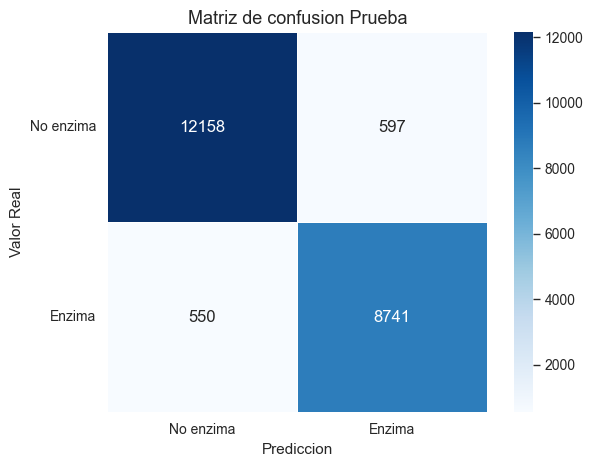

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()
accuracy_v = accuracy_score(y_test, y_pred)
precision_v = precision_score(y_test, y_pred)
recall_v = recall_score(y_test, y_pred)
roc_auc_v = roc_auc_score(y_test, y_pred)
f1_v = f1_score(y_test, y_pred)
conf_matrix_v = confusion_matrix(y_test, y_pred)
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_test, y_pred), sep=f'\n')
class_labels = ['No enzima', 'Enzima']
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Prueba')

## Uncertainty Quantification

In [6]:
valid_emb = np.load(valid_emb_dir)
valid_feat = np.load(valid_feat_dir)
y_valid = np.load(y_valid_dir)
test_emb = np.load(test_emb_dir)
test_feat = np.load(test_feat_dir)
valid = tf.data.Dataset.from_tensor_slices(
    (valid_emb.astype('float64'), valid_feat.astype('float64'))
).batch(64)
test = tf.data.Dataset.from_tensor_slices(
    (test_emb.astype('float64'), test_feat.astype('float64'))
).batch(64)

In [7]:
y_test = np.load(y_test_dir)

In [8]:
@tf.function(reduce_retracing=True)
def binary_entropy(p, eps=1e-12) -> tf.Tensor:
    p = tf.cast(p, tf.float64)
    eps = tf.constant(eps, dtype=p.dtype)
    p = tf.clip_by_value(p, eps, 1. - eps)
    return -(p * tf.math.log(p) + (1 - p) * tf.math.log(1 - p))

class UQ_Classifier(models.Model):
    def __init__(self, model_dir):
        super(UQ_Classifier, self).__init__()
        self.model = models.load_model(model_dir)

    @staticmethod
    def _tensor_key(tensor):
        return tensor.name

    @tf.function
    def _mc_forward_pass(self, x):
        if self.model is None:
            raise ValueError("El modelo no se cargó correctamente.")
        layer_outputs = {}
        model_inputs = x if isinstance(x, (tuple, list)) else (x,)
        for tensor, value in zip(self.model.inputs, model_inputs):
            layer_outputs[self._tensor_key(tensor)] = value
        for layer in self.model.layers:
            if isinstance(layer, layers.InputLayer):
                continue
            inbound = layer.input
            if isinstance(inbound, (list, tuple)):
                layer_input = [layer_outputs[self._tensor_key(t)] for t in inbound]
            else:
                layer_input = layer_outputs[self._tensor_key(inbound)]
            if isinstance(layer, layers.Dropout):
                layer_output = layer(layer_input, training=True)
            elif isinstance(layer, (layers.BatchNormalization, layers.GaussianNoise)):
                layer_output = layer(layer_input, training=False)
            else:
                layer_output = layer(layer_input)
            outbound = layer.output
            if isinstance(outbound, (list, tuple)):
                for tensor, value in zip(outbound, layer_output):
                    layer_outputs[self._tensor_key(tensor)] = value
            else:
                layer_outputs[self._tensor_key(outbound)] = layer_output
        probabilities = tf.cast(layer_outputs[self._tensor_key(self.model.output)], tf.float64)
        eps = tf.constant(1e-12, dtype=probabilities.dtype)
        probabilities = tf.clip_by_value(probabilities, eps, 1. - eps)
        logits = tf.math.log(probabilities) - tf.math.log1p(-probabilities)
        tf.debugging.assert_all_finite(probabilities, "Se detectaron probabilidades no finitas durante MC Dropout.")
        tf.debugging.assert_all_finite(logits, "Se detectaron logits no finitos al reconstruir logits desde probabilidades.")
        return probabilities, logits
    
    def predict_with_uncertainty(self, dataset, T=20):
        all_p_mean = []
        all_logits_mean = []
        all_u = []
        for x_batch in dataset:
            batch_p = []
            batch_logit = []
            for _ in range(T):
                p_t, logits_t = self._mc_forward_pass(x_batch)
                batch_p.append(p_t)
                batch_logit.append(logits_t)

            batch_p = tf.stack(batch_p, axis=0)
            batch_logit = tf.stack(batch_logit, axis=0)
            u_aleatoric = tf.reduce_mean(binary_entropy(batch_p), axis=0)
            p_marginal = tf.reduce_mean(batch_p, axis=0)
            mean_logits = tf.reduce_mean(batch_logit, axis=0)
            u_total = binary_entropy(p_marginal)
            u_epistemic = tf.maximum(u_total - u_aleatoric, 0.0)

            all_p_mean.append(p_marginal)
            all_u.append((u_total, u_aleatoric, u_epistemic))
            all_logits_mean.append(mean_logits)

        return (
            tf.concat(all_p_mean, axis=0),
            tf.concat(all_logits_mean, axis=0),
            tuple(tf.concat(x, axis=0) for x in zip(*all_u))
        )

In [9]:
uq = UQ_Classifier(model_dir)

In [10]:
predictions, logits, uncertainties = uq.predict_with_uncertainty(valid)

### Calibration (Platt Scaling)

In [11]:
predictions = predictions.numpy()
logits = logits.numpy()

In [12]:
from sklearn.linear_model import LogisticRegression


lr_scaler = LogisticRegression(solver='lbfgs', C=1e10) # C alto para no regularizar
lr_scaler.fit(logits, y_valid)

# W = lr_scaler.coef_[0][0]
# b = lr_scaler.intercept_[0]

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10000000000.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For 

In [13]:
t_pred, t_logits, uncertainties = uq.predict_with_uncertainty(test)
t_pred = t_pred.numpy()
t_logits = t_logits.numpy()
scaled_predictions = lr_scaler.predict_proba(t_logits.astype('float32'))[:, 1]

In [14]:
scaled_predictions = scaled_predictions.reshape((-1, 1))

In [15]:
y_test = y_test.reshape((-1, 1))

In [16]:
from sklearn.calibration import calibration_curve
fraction_of_positives, mean_predicted_value = calibration_curve(y_test.reshape((-1, 1)), scaled_predictions, n_bins=10, strategy='quantile')

In [17]:
fraction_of_positives

array([9.07029478e-04, 1.81405896e-03, 8.62068966e-03, 1.13378685e-02,
       6.71506352e-02, 3.03401361e-01, 8.61615245e-01, 9.75510204e-01,
       9.90018149e-01, 9.94104308e-01])

In [18]:
t_pred.shape

(22046, 1)

In [17]:
from sklearn.metrics import brier_score_loss, roc_auc_score

def nll(y_true, p, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(
        y_true * np.log(p) + (1 - y_true) * np.log(1 - p)
    )

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true)
    p = np.asarray(p)
    
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(p, bin_edges, right=True) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)
    
    ece = 0.0
    for b in range(n_bins):
        mask = bin_ids == b
        if np.sum(mask) > 0:
            bin_prob_true = np.mean(y_true[mask])
            bin_prob_pred = np.mean(p[mask])
            bin_weight = np.sum(mask) / len(p)
            ece += bin_weight * np.abs(bin_prob_true - bin_prob_pred)
    
    return ece

roc_auc_uncali = roc_auc_score(y_test, t_pred)
roc_auc_cali = roc_auc_score(y_test, scaled_predictions)
nll_uncali = nll(y_test, t_pred)
nll_cali = nll(y_test, scaled_predictions)
brier_uncali = brier_score_loss(y_test, t_pred)
brier_cali = brier_score_loss(y_test, scaled_predictions)
ece_uncali = expected_calibration_error(y_test, t_pred)
ece_cali = expected_calibration_error(y_test, scaled_predictions)

In [18]:
results = pd.DataFrame({
    "Metric": ["ROC-AUC", "NLL", "Brier Score", "ECE"],
    "Uncalibrated": [
        roc_auc_uncali,
        nll_uncali,
        brier_uncali,
        ece_uncali
    ],
    "Calibrated": [
        roc_auc_cali,
        nll_cali,
        brier_cali,
        ece_cali
    ]
})
results.style.format({
    "Uncalibrated": "{:.4f}",
    "Calibrated": "{:.4f}"
}).highlight_min(
    subset=["Uncalibrated", "Calibrated"],
    color="lightgreen"
)
results

,Metric,Uncalibrated,Calibrated
0,ROC-AUC,0.983850,0.984918
1,NLL,0.176932,0.152602
2,Brier Score,0.047650,0.042562
3,ECE,0.048529,0.009094


In [19]:
from sklearn.calibration import calibration_curve
from scipy import stats
from matplotlib.gridspec import GridSpec

def plot_reliability_diagram(
    y_true, y_pred,
    title="Reliability Diagram",
    n_bins=10,
    show_histogram=True,
    show_density=True,
    figsize=(12, 8),
    color='steelblue',
    calibration_color='darkorange',
    alpha=0.8
):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    quantiles = np.linspace(0.0, 1.0, n_bins + 1)
    bin_edges = np.percentile(y_pred, quantiles * 100)

    bin_ids = np.digitize(y_pred, bin_edges, right=True) - 1
    bin_ids = np.clip(bin_ids, 0, n_bins - 1)

    prob_true = np.zeros(n_bins)
    prob_pred = np.zeros(n_bins)
    bin_counts = np.zeros(n_bins)

    for b in range(n_bins):
        mask = bin_ids == b
        bin_counts[b] = np.sum(mask)

        if bin_counts[b] > 0:
            prob_true[b] = np.mean(y_true[mask])
            prob_pred[b] = np.mean(y_pred[mask])
        else:
            prob_true[b] = np.nan
            prob_pred[b] = np.nan

    brier = brier_score_loss(y_true, y_pred)
    ece = expected_calibration_error(y_true, y_pred)
    n_l_l = nll(y_true, y_pred)

    if show_histogram:
        fig = plt.figure(figsize=figsize)
        gs = GridSpec(2, 2, height_ratios=[3, 1], width_ratios=[3, 1])
        ax = fig.add_subplot(gs[0, 0])
        ax_histx = fig.add_subplot(gs[1, 0], sharex=ax)
        ax_histy = fig.add_subplot(gs[0, 1], sharey=ax)
    else:
        fig, ax = plt.subplots(figsize=figsize)
        ax_histx = ax_histy = None

    ax.plot([0, 1], [0, 1], "k--", lw=2, label="Calibración perfecta")

    # Curva de calibración
    ax.plot(
        prob_pred, prob_true,
        marker='s',
        color=calibration_color,
        linewidth=3,
        markersize=8,
        markerfacecolor='white',
        markeredgewidth=2,
        label="Curva de calibración"
    )

    if show_density and np.sum(y_true == 1) > 5:
        kde = stats.gaussian_kde(y_pred[y_true == 1])
        x = np.linspace(0, 1, 300)
        y = kde(x)
        y = y / y.max() * 0.3
        ax.fill_between(x, 0, y, color='green', alpha=0.2,
                        label="Densidad (clase positiva)")

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xlabel("Probabilidades producidas", fontweight='bold')
    ax.set_ylabel("Fracción de positivos", fontweight='bold')
    ax.set_title(title, fontweight='bold')
    ax.grid(True, linestyle='--', alpha=0.3)

    text = (
        f"Brier: {brier:.6f}\n"
        f"NLL: {n_l_l:.6f}\n"
        f"ECE: {ece:.6f}\n"
        f"Positives: {int(y_true.sum())}/{len(y_true)}"
    )
    ax.text(0.02, 0.98, text, transform=ax.transAxes,
            va='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

    ax.legend(loc='lower right')

    if show_histogram:
        ax_histx.hist(y_pred, bins=quantiles, color=color,
                      alpha=alpha, edgecolor='black')
        ax_histx.set_ylabel("Count")
        ax_histx.grid(True, alpha=0.3)

        ax_histy.hist(y_true, bins=2, orientation='horizontal',
                      color='gray', alpha=0.7, edgecolor='black')
        ax_histy.set_xlabel("Count")
        ax_histy.grid(True, alpha=0.3)

    plt.tight_layout()


    return fig


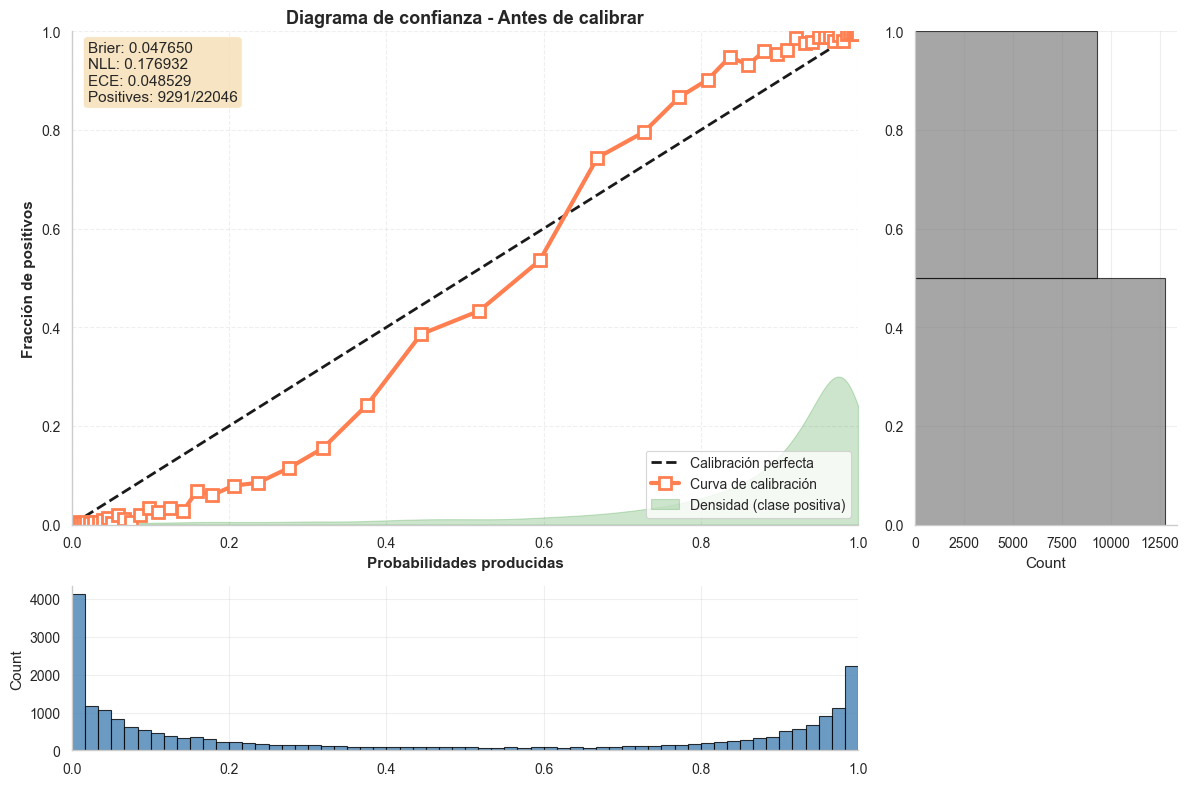

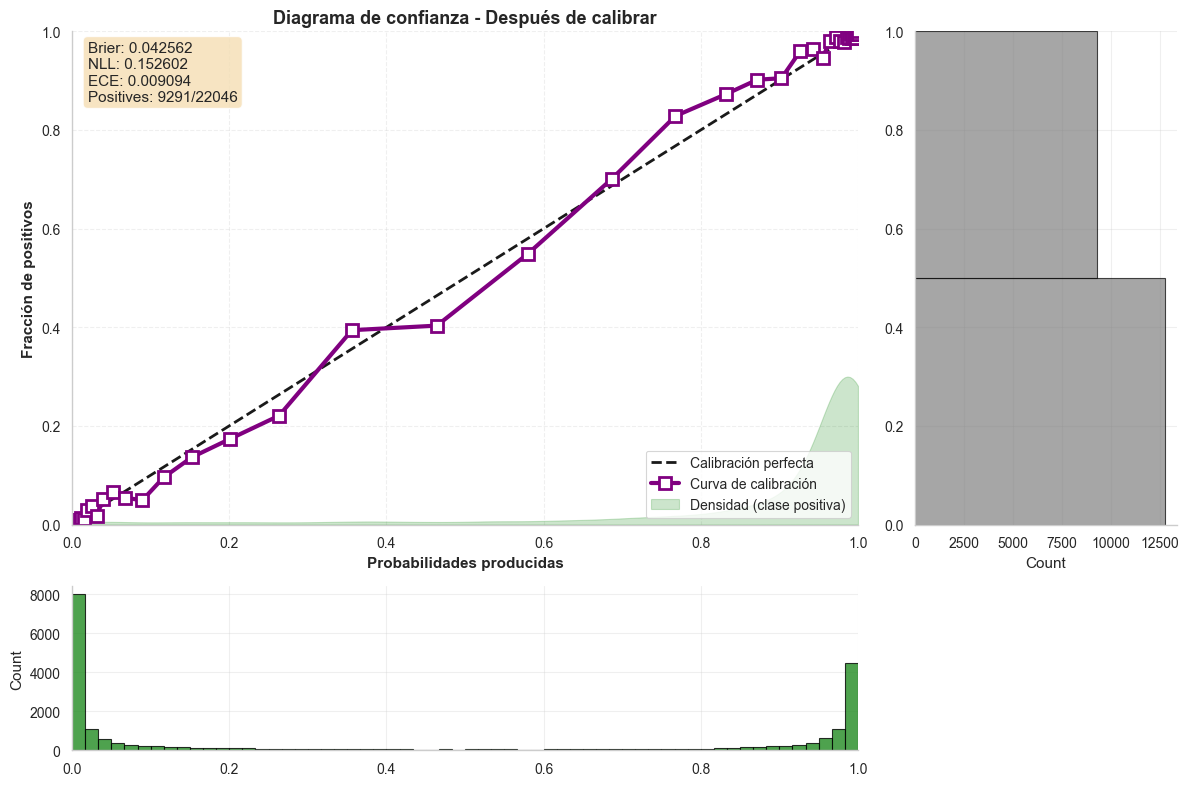

In [20]:
fig_before = plot_reliability_diagram(
    y_test, t_pred,
    title="Diagrama de confianza - Antes de calibrar",
    n_bins=60,
    show_histogram=True,
    show_density=True,
    color='steelblue',
    calibration_color='coral'
)

fig_after = plot_reliability_diagram(
    y_test, scaled_predictions,
    title="Diagrama de confianza - Después de calibrar",
    n_bins=60,
    show_histogram=True,
    show_density=True,
    color='forestgreen',
    calibration_color='purple'
)
plt.show()

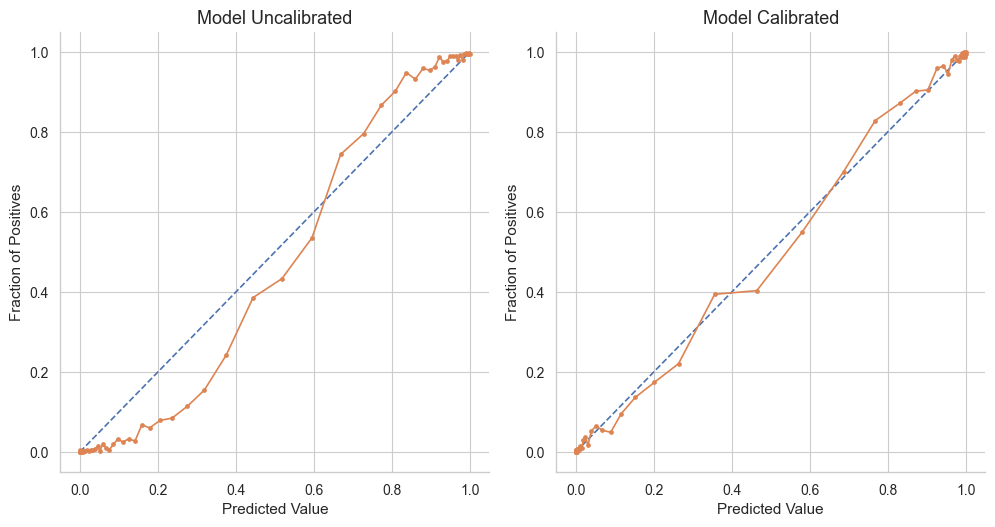

In [21]:
from sklearn.calibration import calibration_curve
def plot_calibration_curve(y, pred, cali_pred):
    plt.figure(figsize=(20, 20))
    plt.subplot(4, 4, 1)
    fraction_of_positives, mean_predicted_value = calibration_curve(y, pred, n_bins=60, strategy='quantile')
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.plot(mean_predicted_value, fraction_of_positives, marker='.')
    plt.xlabel("Predicted Value")
    plt.ylabel("Fraction of Positives")
    plt.title('Model Uncalibrated')
    

    plt.subplot(4, 4, 2)
    fraction_of_positives, mean_predicted_value = calibration_curve(y, cali_pred, n_bins=60, strategy='quantile')
    plt.plot([0, 1], [0, 1], linestyle='--')
    plt.plot(mean_predicted_value, fraction_of_positives, marker='.')
    plt.xlabel("Predicted Value")
    plt.ylabel("Fraction of Positives")
    plt.title('Model Calibrated')
    plt.tight_layout()
    plt.show()

plot_calibration_curve(y_test, t_pred, scaled_predictions)

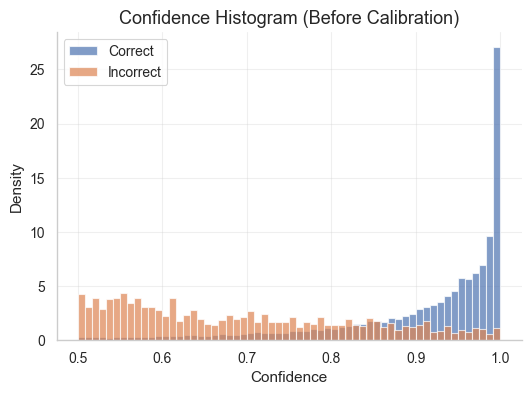

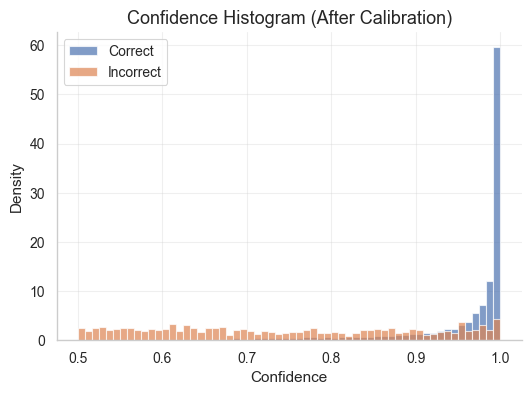

In [22]:
def plot_confidence_histogram(p, y_true=None, title="", bins=60):
    """
    p: array de probabilidades p(y=1|x)
    y_true: opcional, etiquetas reales para separar correctos/incorrectos
    """
    confidence = np.maximum(p, 1 - p)

    plt.figure(figsize=(6, 4))

    if y_true is None:
        plt.hist(confidence, bins=bins, density=True, alpha=0.8)
    else:
        preds = (p >= 0.5).astype(int)
        correct = preds == y_true

        plt.hist(confidence[correct], bins=bins, density=True,
                 alpha=0.7, label="Correct")
        plt.hist(confidence[~correct], bins=bins, density=True,
                 alpha=0.7, label="Incorrect")

        plt.legend()

    plt.xlabel("Confidence")
    plt.ylabel("Density")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.show()

plot_confidence_histogram(
    t_pred,
    y_test,
    title="Confidence Histogram (Before Calibration)"
)
plot_confidence_histogram(
    scaled_predictions,
    y_test,
    title="Confidence Histogram (After Calibration)"
)

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, brier_score_loss

def plot_confidence_histogram(
    y_true,
    y_pred_prob_positive,
    y_pred_labels=None,
    threshold=0.5,
    n_bins=10,
    model_name="Modelo"
):
    """
    Histograma de confianza: usa la confianza de la predicción realizada.

    Parámetros:
    -----------
    y_true : array
        Etiquetas verdaderas (0/1 o one-hot).
    y_pred_prob_positive : array
        - Binario: probabilidades de la clase positiva, o matriz (n,2) con [P(0), P(1)]
        - Multiclase: matriz (n,C) con probabilidades por clase
    y_pred_labels : array, opcional
        Etiquetas predichas. Si None, se calculan automáticamente.
    threshold : float
        Umbral para clasificación binaria cuando y_pred_labels es None y la salida es 1D.
    n_bins : int
        Número de intervalos para el histograma.
    model_name : str
        Nombre del modelo para el título.
    """

    y_true = np.asarray(y_true)
    y_pred_prob_positive = np.asarray(y_pred_prob_positive)

    # =========================
    # 1) NORMALIZACIÓN DE ENTRADAS
    # =========================

    # Etiquetas verdaderas
    if y_true.ndim > 1:
        if y_true.shape[1] == 1:
            y_true_labels = y_true.ravel().astype(int)
        else:
            y_true_labels = np.argmax(y_true, axis=1).astype(int)
    else:
        y_true_labels = y_true.astype(int)

    # Detectar binario vs multiclase
    # Binario si:
    # - salida 1D (probabilidad de clase positiva)
    # - o salida 2D con 1 o 2 columnas
    is_binary = (
        y_pred_prob_positive.ndim == 1
        or (y_pred_prob_positive.ndim == 2 and y_pred_prob_positive.shape[1] <= 2)
    )

    # =========================
    # 2) PREDICCIONES, CONFIANZA Y PROBABILIDADES PARA MÉTRICAS
    # =========================

    if is_binary:
        # Probabilidad de clase positiva
        if y_pred_prob_positive.ndim == 2:
            if y_pred_prob_positive.shape[1] == 2:
                p_pos = y_pred_prob_positive[:, 1]
                p_neg = y_pred_prob_positive[:, 0]
            else:  # shape (n,1)
                p_pos = y_pred_prob_positive[:, 0]
                p_neg = 1.0 - p_pos
        else:
            p_pos = y_pred_prob_positive.astype(float)
            p_neg = 1.0 - p_pos

        # Etiqueta predicha
        if y_pred_labels is None:
            if y_pred_prob_positive.ndim == 2 and y_pred_prob_positive.shape[1] == 2:
                y_pred_labels = np.argmax(y_pred_prob_positive, axis=1).astype(int)
            else:
                y_pred_labels = (p_pos >= threshold).astype(int)
        else:
            y_pred_labels = np.asarray(y_pred_labels)
            if y_pred_labels.ndim > 1:
                y_pred_labels = np.argmax(y_pred_labels, axis=1)
            y_pred_labels = y_pred_labels.astype(int)

        # Confianza de la predicción realizada:
        # P(\hat y|x) = p_pos si predice 1, 1-p_pos si predice 0
        confidence = np.where(y_pred_labels == 1, p_pos, p_neg)

        # En binario, la confianza top-label está en [0.5, 1]
        bins = np.linspace(0.5, 1.0, n_bins + 1)

        # Métricas de discriminación/calibración deben usar p_pos, no confidence
        try:
            AUC_ROC = roc_auc_score(y_true_labels, p_pos)
        except ValueError:
            AUC_ROC = np.nan

        try:
            brier_score = brier_score_loss(y_true_labels, p_pos)
        except ValueError:
            brier_score = np.nan

    else:
        # Multiclase
        if y_pred_labels is None:
            y_pred_labels = np.argmax(y_pred_prob_positive, axis=1).astype(int)
        else:
            y_pred_labels = np.asarray(y_pred_labels)
            if y_pred_labels.ndim > 1:
                y_pred_labels = np.argmax(y_pred_labels, axis=1)
            y_pred_labels = y_pred_labels.astype(int)

        # Confianza top-label: max_k p_k(x)
        confidence = np.max(y_pred_prob_positive, axis=1)
        bins = np.linspace(0.0, 1.0, n_bins + 1)

        # AUC macro OVR
        try:
            AUC_ROC = roc_auc_score(
                y_true_labels,
                y_pred_prob_positive,
                multi_class="ovr",
                average="macro"
            )
        except ValueError:
            AUC_ROC = np.nan

        # Brier multiclass: media del error cuadrático respecto a one-hot
        try:
            n_classes = y_pred_prob_positive.shape[1]
            y_true_onehot = np.eye(n_classes)[y_true_labels]
            brier_score = np.mean(np.sum((y_pred_prob_positive - y_true_onehot) ** 2, axis=1))
        except Exception:
            brier_score = np.nan

    # =========================
    # 3) CORRECTAS / INCORRECTAS
    # =========================

    correct = (y_pred_labels == y_true_labels)
    incorrect = ~correct

    # =========================
    # 4) HISTOGRAMA POR BINS
    # =========================

    bin_centers = (bins[:-1] + bins[1:]) / 2
    width = (bins[1] - bins[0]) * 0.38

    conf_correct = confidence[correct]
    conf_incorrect = confidence[incorrect]

    counts_correct, _ = np.histogram(conf_correct, bins=bins)
    counts_incorrect, _ = np.histogram(conf_incorrect, bins=bins)
    total_counts = counts_correct + counts_incorrect

    # =========================
    # 5) TASA DE ERROR POR BIN
    # =========================

    error_rate_by_bin = []
    n_samples_by_bin = []

    for i in range(n_bins):
        mask = (confidence >= bins[i]) & (confidence < bins[i + 1])
        if i == n_bins - 1:
            mask = (confidence >= bins[i]) & (confidence <= bins[i + 1])

        n_samples = np.sum(mask)
        n_samples_by_bin.append(n_samples)

        if n_samples > 0:
            error_rate = np.sum(y_pred_labels[mask] != y_true_labels[mask]) / n_samples
            error_rate_by_bin.append(error_rate)
        else:
            error_rate_by_bin.append(0.0)

    total_samples = len(y_true_labels)

    # =========================
    # 6) ECE SOBRE CONFIANZA TOP-LABEL
    # =========================

    def _confidence_ece(confidence_values, correct_mask, bin_edges):
        if len(confidence_values) == 0:
            return 0.0

        bin_ids = np.digitize(confidence_values, bin_edges, right=True) - 1
        bin_ids = np.clip(bin_ids, 0, len(bin_edges) - 2)

        ece_value = 0.0
        total = len(confidence_values)

        for b in range(len(bin_edges) - 1):
            mask = bin_ids == b
            if np.sum(mask) > 0:
                bin_acc = np.mean(correct_mask[mask])
                bin_conf = np.mean(confidence_values[mask])
                ece_value += (np.sum(mask) / total) * abs(bin_acc - bin_conf)

        return ece_value

    ece = _confidence_ece(confidence, correct, bins)

    # =========================
    # 7) ALTA CONFIANZA, DISTRIBUCIÓN Y RESUMEN
    # =========================

    high_conf_mask = confidence >= 0.9
    n_high_conf = np.sum(high_conf_mask)

    if n_high_conf > 0:
        high_conf_error_rate = np.sum(
            y_pred_labels[high_conf_mask] != y_true_labels[high_conf_mask]
        ) / n_high_conf
    else:
        high_conf_error_rate = 0.0

    low_conf = np.sum(confidence < 0.6) / total_samples if total_samples > 0 else 0.0
    medium_conf = np.sum((confidence >= 0.6) & (confidence < 0.8)) / total_samples if total_samples > 0 else 0.0
    high_conf = np.sum(confidence >= 0.8) / total_samples if total_samples > 0 else 0.0

    avg_conf_all = np.mean(confidence) if total_samples > 0 else 0.0
    avg_conf_correct = np.mean(confidence[correct]) if np.sum(correct) > 0 else 0.0
    avg_conf_incorrect = np.mean(confidence[incorrect]) if np.sum(incorrect) > 0 else 0.0

    # =========================
    # 8) GRÁFICO
    # =========================

    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle(f'Histograma de Confianza - {model_name}',
                 fontsize=16, fontweight='bold')

    # SUBPLOT 1: HISTOGRAMA DE CONFIANZA
    ax1 = axes[0, 0]

    ax1.bar(bin_centers - width/2, counts_correct, width=width,
            alpha=0.7, label='Correctas', color='#2ecc71',
            edgecolor='black', linewidth=0.5)
    ax1.bar(bin_centers + width/2, counts_incorrect, width=width,
            alpha=0.7, label='Incorrectas', color='#e74c3c',
            edgecolor='black', linewidth=0.5)

    ax1.set_xlabel('Confianza del Modelo (max(P(clase)))', fontsize=12)
    ax1.set_ylabel('Número de Muestras', fontsize=12)
    ax1.set_title('Distribución de Confianza por Exactitud de Predicción', fontsize=14)
    ax1.legend(loc='upper left')
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.set_xlim(bins[0], bins[-1])

    for i, (corr, incorr) in enumerate(zip(counts_correct, counts_incorrect)):
        total = corr + incorr
        if total > 0:
            percentage = corr / total
            ax1.text(
                bin_centers[i],
                max(corr, incorr) + max(total_counts) * 0.02 if np.max(total_counts) > 0 else 0.02,
                f'{percentage:.0%}',
                ha='center',
                fontsize=9,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7)
            )

    ax1.axvline(x=0.5, color='gray', linestyle='--', alpha=0.5)

    # SUBPLOT 2: TASA DE ERROR POR NIVEL DE CONFIANZA
    ax2 = axes[0, 1]

    bars = ax2.bar(
        bin_centers,
        error_rate_by_bin,
        width=width*2,
        color=['#e74c3c' if rate > 0.5 else
               '#f39c12' if rate > 0.2 else
               '#2ecc71' for rate in error_rate_by_bin],
        edgecolor='black',
        linewidth=1
    )

    for i, (err_rate, n_samples) in enumerate(zip(error_rate_by_bin, n_samples_by_bin)):
        if err_rate > 0.5 and bins[i] > 0.8:
            bars[i].set_hatch('//')
            bars[i].set_linewidth(2)
            ax2.text(
                bin_centers[i],
                err_rate + 0.03,
                "⚠ PELIGRO",
                ha='center',
                fontsize=10,
                fontweight='bold',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.8)
            )

        if n_samples > 0:
            ax2.text(
                bin_centers[i],
                err_rate / 2,
                f'n={n_samples}',
                ha='center',
                fontsize=8,
                color='white',
                fontweight='bold'
            )

    ax2.set_xlabel('Intervalo de Confianza', fontsize=12)
    ax2.set_ylabel('Tasa de Error', fontsize=12)
    ax2.set_title('Tasa de Error por Nivel de Confianza', fontsize=14)
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.set_ylim(0, 1)

    # SUBPLOT 3 Y 4: TEXTO
    ax3 = axes[1, 0]
    ax3.axis('off')
    ax4 = axes[1, 1]
    ax4.axis('off')

    high_conf_rate = (n_high_conf / total_samples) if total_samples > 0 else 0.0

    metrics_text = (
        f'RESUMEN DEL MODELO - CONFIANZA CORREGIDA\n{"="*45}\n\n'
        f'• AUC-ROC Score: {AUC_ROC:.2%}\n'
        f'• Brier Score: {brier_score:.4f}\n'
        f'• Expected Calibration Error (ECE): {ece:.4f}\n\n'

        f'CONFIANZA PROMEDIO\n{"="*20}\n'
        f'• Todas las muestras: {avg_conf_all:.3f}\n'
        f'• Predicciones CORRECTAS: {avg_conf_correct:.3f}\n'
        f'• Predicciones INCORRECTAS: {avg_conf_incorrect:.3f}\n'
        f'• Diferencia: {avg_conf_correct - avg_conf_incorrect:.3f}\n\n'

        f'DISTRIBUCIÓN DE CONFIANZA\n{"="*25}\n'
        f'• Baja (<0.6): {low_conf:.1%}\n'
        f'• Media (0.6-0.8): {medium_conf:.1%}\n'
        f'• Alta (>0.8): {high_conf:.1%}\n\n'

        f'ANÁLISIS DE RIESGO\n{"="*20}\n'
        f'• Error en alta confianza (>0.9): {high_conf_error_rate:.2%}\n'
        f'• Muestras de alta confianza: {n_high_conf} ({high_conf_rate:.1%})\n'
        f'• Máximo error tolerable: <5%\n'
    )

    if ece < 0.01:
        cal_grade = "★ EXCELENTE ★"
        cal_color = "green"
    elif ece < 0.05:
        cal_grade = "✓ BUENO"
        cal_color = "orange"
    elif ece < 0.1:
        cal_grade = "⚠ ACEPTABLE"
        cal_color = "darkorange"
    else:
        cal_grade = "✗ REQUIERE RECALIBRACIÓN"
        cal_color = "red"

    ax3.text(
        0.05, 0.95, metrics_text,
        transform=ax3.transAxes,
        fontsize=10,
        verticalalignment='top',
        fontfamily='monospace'
    )

    plt.tight_layout()
    plt.show()

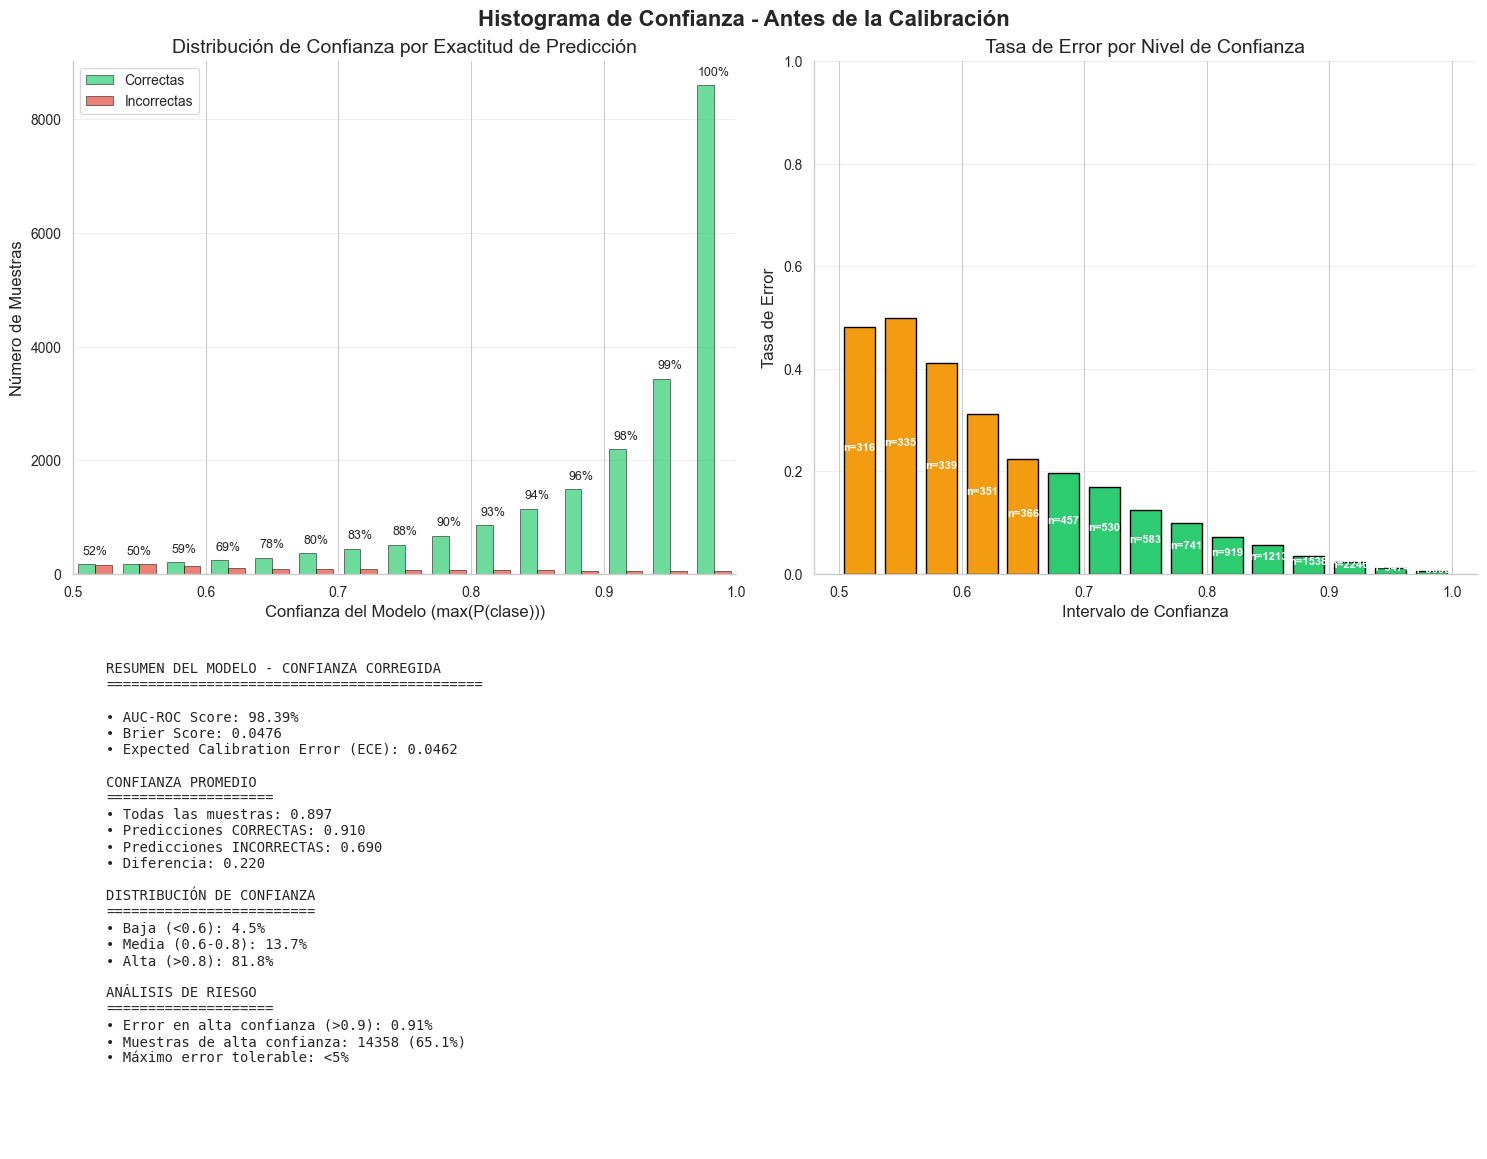

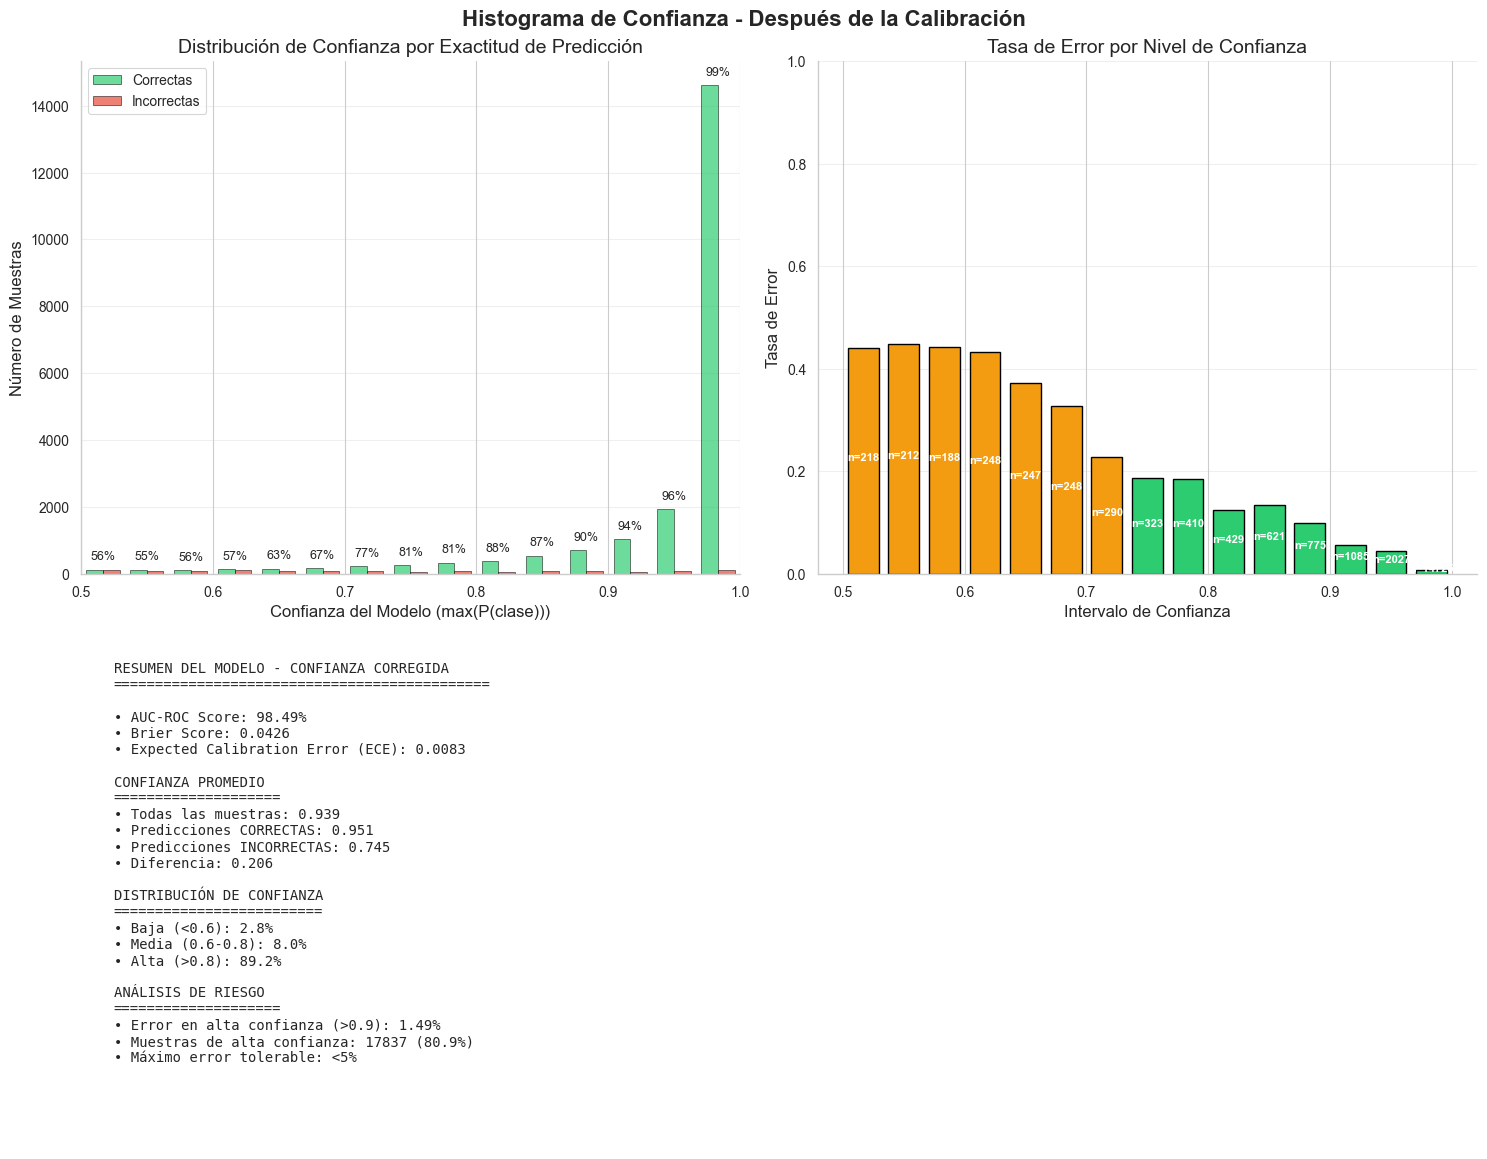

In [24]:
plot_confidence_histogram(y_test, t_pred, n_bins=15, model_name="Antes de la Calibración")
plot_confidence_histogram(y_test, scaled_predictions, n_bins=15, model_name="Después de la Calibración")

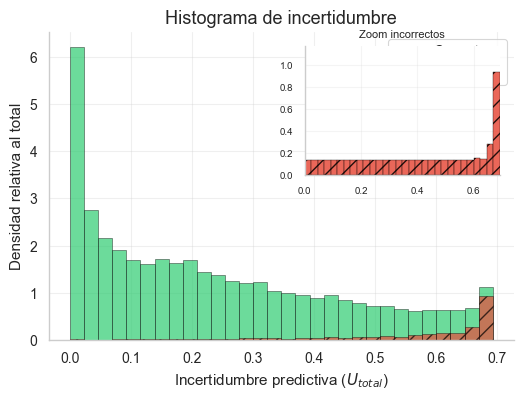

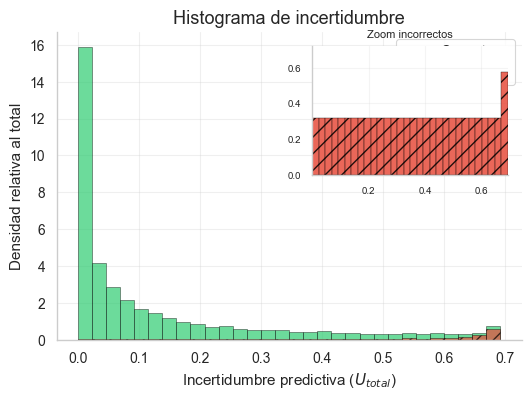

In [25]:
def plot_entropy_histogram(y_true, pred, title="", bins=30):
    entropy = binary_entropy(pred)
    preds = (pred >= 0.5).astype(int)
    correct = preds == y_true
    bin_edges = np.histogram_bin_edges(entropy, bins=bins)

    counts_correct, _ = np.histogram(entropy[correct], bins=bin_edges)
    counts_incorrect, _ = np.histogram(entropy[~correct], bins=bin_edges)
    total = max(len(entropy), 1)
    bin_widths = np.diff(bin_edges)

    correct_density = counts_correct / (total * bin_widths)
    incorrect_density = counts_incorrect / (total * bin_widths)

    fig, ax = plt.subplots(figsize=(6, 4))
    ax.bar(
        bin_edges[:-1],
        correct_density,
        width=bin_widths,
        align="edge",
        alpha=0.7,
        label="Correctos",
        color="#2ecc71",
        edgecolor="black",
        linewidth=0.4,
    )
    ax.bar(
        bin_edges[:-1],
        incorrect_density,
        width=bin_widths,
        align="edge",
        alpha=0.7,
        label="Incorrectos",
        color="#e74c3c",
        edgecolor="black",
        linewidth=0.4,
        hatch="//",
    )

    ax.set_xlabel("Incertidumbre predictiva ($U_{total}$)")
    ax.set_ylabel("Densidad relativa al total")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

    try:
        from mpl_toolkits.axes_grid1.inset_locator import inset_axes

        axins = inset_axes(ax, width="42%", height="42%", loc="upper right", borderpad=1)
        max_incorrect = float(incorrect_density.max()) if len(incorrect_density) else 0.0
        min_visible_height = max(max_incorrect * 0.15, float(correct_density.max()) * 0.02 if len(correct_density) else 0.0, 1e-12)
        incorrect_zoom = np.where(incorrect_density > 0, np.maximum(incorrect_density, min_visible_height), 0.0)
        axins.bar(
            bin_edges[:-1],
            incorrect_zoom,
            width=bin_widths,
            align="edge",
            alpha=0.85,
            color="#e74c3c",
            edgecolor="black",
            linewidth=0.3,
            hatch="//",
        )
        axins.set_title("Zoom incorrectos", fontsize=8)
        axins.set_xlim(bin_edges[0], bin_edges[-1])
        axins.set_ylim(0, max(float(incorrect_zoom.max()) * 1.25, min_visible_height * 1.25))
        axins.tick_params(axis="both", labelsize=7)
        axins.grid(True, alpha=0.2)
    except Exception:
        pass

    plt.show()

plot_entropy_histogram(y_test, t_pred, title="Histograma de incertidumbre")
plot_entropy_histogram(y_test, scaled_predictions, title="Histograma de incertidumbre")

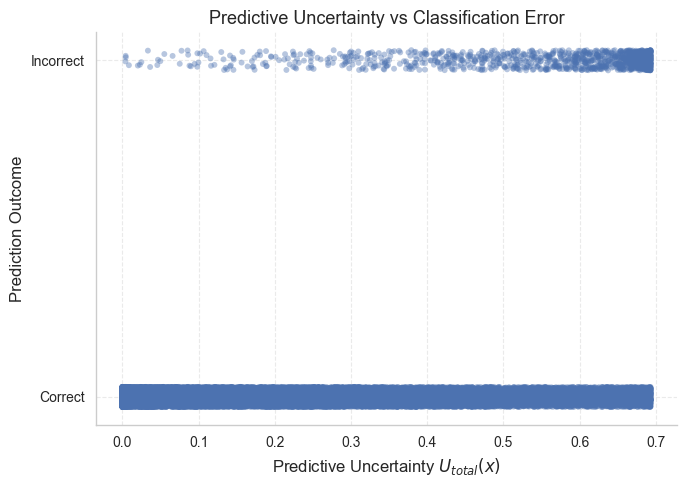

In [26]:
def plot_uncertainty_vs_error(
    u_total,
    y_true,
    p_mean,
    threshold=0.5,
    jitter=0.03,
    figsize=(7, 5)
):
    """
    Scatter plot: U_total vs error

    Parameters
    ----------
    u_total : np.ndarray (N,)
        Predictive entropy per sample
    y_true : np.ndarray (N,)
        True binary labels
    p_mean : np.ndarray (N,)
        Marginal predicted probabilities
    threshold : float
        Decision threshold
    jitter : float
        Vertical jitter magnitude
    """

    # Binary predictions
    y_pred = (p_mean >= threshold).astype(int)

    # Error (0 = correct, 1 = incorrect)
    error = (y_pred != y_true).astype(int)

    # Add jitter for visualization
    error_jittered = error + np.random.uniform(
        low=-jitter, high=jitter, size=len(error)
    ).reshape((-1, 1))

    plt.figure(figsize=figsize)

    plt.scatter(
        u_total,
        error_jittered,
        alpha=0.4,
        s=18,
        edgecolors="none"
    )

    plt.yticks([0, 1], ["Correct", "Incorrect"])
    plt.xlabel("Predictive Uncertainty $U_{total}(x)$", fontsize=12)
    plt.ylabel("Prediction Outcome", fontsize=12)

    plt.title(
        "Predictive Uncertainty vs Classification Error",
        fontsize=13
    )

    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()
plot_uncertainty_vs_error(
    uncertainties[0].numpy(),  # U_total
    y_test,                    # True labels
    t_pred,       # p_mean
    threshold=0.5,
    jitter=0.03,
    figsize=(7, 5)
)

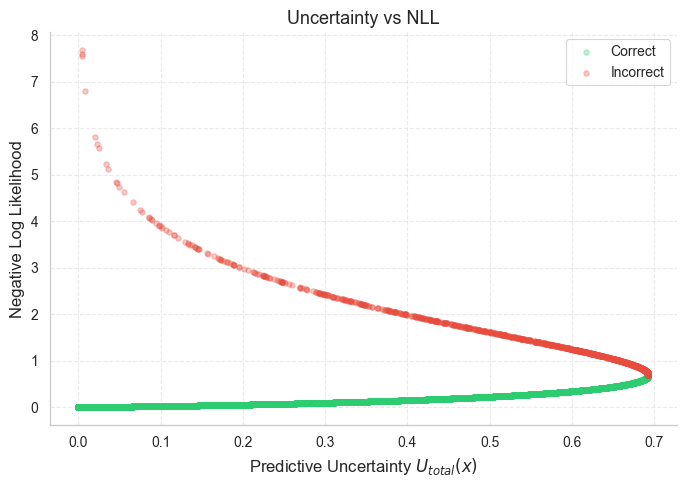

In [27]:
def plot_uncertainty_vs_nll(
    u_total,
    y_true,
    p_mean,
    x_label,
    y_label,
    title,
    n_bins=10,
    threshold=0.5,
    figsize=(7, 5)
):
    y_pred = (p_mean >= threshold).astype(int)
    loss = -(
        y_true * np.log(p_mean + 1e-8)
        + (1 - y_true) * np.log(1 - p_mean + 1e-8)
    )
    correct = (y_pred == y_true).astype(bool)
    incorrect = ~correct.astype(bool)

    # Scatter
    plt.figure(figsize=figsize)
    plt.scatter(
        u_total[correct],
        loss[correct],
        color='#2ecc71',
        alpha=0.3,
        s=15,
        label="Correct"
    )
    plt.scatter(
        u_total[incorrect],
        loss[incorrect],
        color='#e74c3c',
        alpha=0.3,
        s=15,
        label="Incorrect"
    )

    

    plt.xlabel(x_label, fontsize=12)
    plt.ylabel(y_label, fontsize=12)
    plt.title(title, fontsize=13)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()

plot_uncertainty_vs_nll(
    uncertainties[0].numpy(),
    y_test,
    t_pred,
    x_label="Predictive Uncertainty $U_{total}(x)$",
    y_label="Negative Log Likelihood",
    title="Uncertainty vs NLL",
    n_bins=10,
    threshold=0.5,
    figsize=(7, 5)
)


In [28]:
from scipy.stats import spearmanr
loss = -(
    y_test * np.log(t_pred + 1e-7)
    + (1 - y_test) * np.log(1 - t_pred + 1e-7)
)
rho, p_value = spearmanr(uncertainties[0].numpy(), loss)
print(f"Spearman ρ = {rho:.3f}, p-value = {p_value:.2e}")

Spearman ρ = 0.984, p-value = 0.00e+00


In [29]:
y_pred = (scaled_predictions >= 0.5).astype(int)


In [30]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Accuracy test: 0.9440
Precision test: 0.9350
Recall test: 0.9319
AUC test: 0.9423
F1-score test: 0.9334
Clasification report test:
              precision    recall  f1-score   support

           0       0.95      0.95      0.95     12755
           1       0.93      0.93      0.93      9291

    accuracy                           0.94     22046
   macro avg       0.94      0.94      0.94     22046
weighted avg       0.94      0.94      0.94     22046



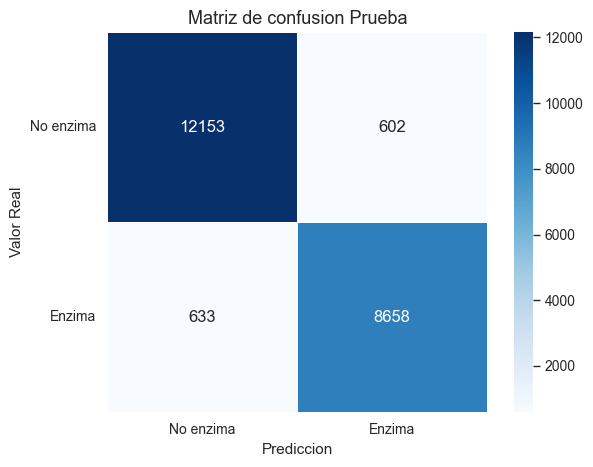

In [31]:
accuracy_v = accuracy_score(y_test, y_pred)
precision_v = precision_score(y_test, y_pred)
recall_v = recall_score(y_test, y_pred)
roc_auc_v = roc_auc_score(y_test, y_pred)
f1_v = f1_score(y_test, y_pred)
conf_matrix_v = confusion_matrix(y_test, y_pred)
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_test, y_pred), sep=f'\n')
class_labels = ['No enzima', 'Enzima']
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Prueba')

### Validar como aumentan las medidas de calidad a medida que se van eliminando las secuencias de más incertidumbre

In [32]:
u_total = uncertainties[0].numpy()

In [35]:
u_total.shape

(22046, 1)

In [33]:
index = np.array([i for i in range(len(u_total))])
combined = np.concatenate((u_total, index.reshape(-1, 1)), axis=1)

In [34]:
sorted_u = combined[combined[:,0].argsort()[::-1]]

#### Para el 5%

In [35]:
percent = 5
total_r = int(len(sorted_u) * percent/100)
filter_index = sorted_u[total_r:, 1].astype(int)

In [36]:
filter_emb = test_emb[filter_index]
filter_feat = test_feat[filter_index]
y_filter = y_test[filter_index]

In [37]:
filtered = tf.data.Dataset.from_tensor_slices(
    (filter_emb.astype('float64'), filter_feat.astype('float64'))
).batch(64)

In [38]:
f_pred, f_logits, f_uncertainties = uq.predict_with_uncertainty(filtered)
f_pred = f_pred.numpy()
f_logits = f_logits.numpy()
f_scaled_predictions = lr_scaler.predict_proba(f_logits.astype('float32'))[:, 1]

In [39]:
y_pred_f = (f_scaled_predictions >= 0.5).astype(int)

In [40]:
accuracy_v = accuracy_score(y_filter, y_pred_f)
precision_v = precision_score(y_filter, y_pred_f)
recall_v = recall_score(y_filter, y_pred_f)
roc_auc_v = roc_auc_score(y_filter, y_pred_f)
f1_v = f1_score(y_filter, y_pred_f)
conf_matrix_v = confusion_matrix(y_filter, y_pred_f)
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_filter, y_pred_f), sep=f'\n')

Accuracy test: 0.9612
Precision test: 0.9509
Recall test: 0.9573
AUC test: 0.9606
F1-score test: 0.9541
Clasification report test:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97     12122
           1       0.95      0.96      0.95      8822

    accuracy                           0.96     20944
   macro avg       0.96      0.96      0.96     20944
weighted avg       0.96      0.96      0.96     20944



#### Para el 10%

In [41]:
percent = 10
total_r = int(len(sorted_u) * percent/100)
filter_index = sorted_u[total_r:, 1].astype(int)

In [42]:
filter_emb = test_emb[filter_index]
filter_feat = test_feat[filter_index]
y_filter = y_test[filter_index]

In [43]:
filtered = tf.data.Dataset.from_tensor_slices(
    (filter_emb.astype('float64'), filter_feat.astype('float64'))
).batch(64)

In [44]:
f_pred, f_logits, f_uncertainties = uq.predict_with_uncertainty(filtered)
f_pred = f_pred.numpy()
f_logits = f_logits.numpy()
f_scaled_predictions = lr_scaler.predict_proba(f_logits.astype('float32'))[:, 1]

In [45]:
y_pred_f = (f_scaled_predictions >= 0.5).astype(int)

In [46]:
accuracy_v = accuracy_score(y_filter, y_pred_f)
precision_v = precision_score(y_filter, y_pred_f)
recall_v = recall_score(y_filter, y_pred_f)
roc_auc_v = roc_auc_score(y_filter, y_pred_f)
f1_v = f1_score(y_filter, y_pred_f)
conf_matrix_v = confusion_matrix(y_filter, y_pred_f)
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_filter, y_pred_f), sep=f'\n')

Accuracy test: 0.9728
Precision test: 0.9641
Recall test: 0.9717
AUC test: 0.9726
F1-score test: 0.9679
Clasification report test:
              precision    recall  f1-score   support

           0       0.98      0.97      0.98     11469
           1       0.96      0.97      0.97      8373

    accuracy                           0.97     19842
   macro avg       0.97      0.97      0.97     19842
weighted avg       0.97      0.97      0.97     19842



#### Para el 20%

In [47]:
percent = 20
total_r = int(len(sorted_u) * percent/100)
filter_index = sorted_u[total_r:, 1].astype(int)

In [48]:
filter_emb = test_emb[filter_index]
filter_feat = test_feat[filter_index]
y_filter = y_test[filter_index]

In [49]:
filtered = tf.data.Dataset.from_tensor_slices(
    (filter_emb.astype('float64'), filter_feat.astype('float64'))
).batch(64)

In [50]:
f_pred, f_logits, f_uncertainties = uq.predict_with_uncertainty(filtered)
f_pred = f_pred.numpy()
f_logits = f_logits.numpy()
f_scaled_predictions = lr_scaler.predict_proba(f_logits.astype('float32'))[:, 1]

In [51]:
y_pred_f = (f_scaled_predictions >= 0.5).astype(int)

In [52]:
accuracy_v = accuracy_score(y_filter, y_pred_f)
precision_v = precision_score(y_filter, y_pred_f)
recall_v = recall_score(y_filter, y_pred_f)
roc_auc_v = roc_auc_score(y_filter, y_pred_f)
f1_v = f1_score(y_filter, y_pred_f)
conf_matrix_v = confusion_matrix(y_filter, y_pred_f)
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report test:", classification_report(y_filter, y_pred_f), sep=f'\n')

Accuracy test: 0.9836
Precision test: 0.9778
Recall test: 0.9831
AUC test: 0.9835
F1-score test: 0.9805
Clasification report test:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99     10231
           1       0.98      0.98      0.98      7406

    accuracy                           0.98     17637
   macro avg       0.98      0.98      0.98     17637
weighted avg       0.98      0.98      0.98     17637

